In [74]:
import numpy as np
import pandas as pd
from matplotlib import pyplot as plt

Read in output csv from survey. To Run Have CS424_Study - Responses.csv loaded into directory. Can be found on GitHub repository under Assignment 3 _> CSV Outputs

In [75]:
output_dataset=pd.read_csv('CS424_Study - Responses.csv')

Open Up and Explore the Dataset

In [48]:
print(output_dataset)

                submitted_at participant_id  group    condition  task  route  \
0   2026-11-06T18:22:35.205Z              8      2  Interactive     1     22   
1   2026-11-06T18:26:20.274Z              8      2  Interactive     2     36   
2   2026-11-06T18:29:16.949Z              8      2       Static     1    147   
3   2026-11-06T18:34:31.024Z              8      2       Static     2    146   
4   2026-11-06T19:28:51.852Z          p1864      1       Static     1     22   
5   2026-11-06T19:32:34.023Z          p1864      1       Static     2     36   
6   2026-11-06T19:40:35.472Z          p1864      1  Interactive     1    147   
7   2026-11-06T19:48:00.672Z          p1864      1  Interactive     2    146   
8   2026-11-07T01:54:47.612Z           P007      2  Interactive     1     22   
9   2026-11-07T02:03:39.446Z           P007      2  Interactive     2     36   
10  2026-11-07T02:06:57.295Z           P007      2       Static     1    147   
11  2026-11-07T02:09:31.795Z           P

Check if missing values--each respondent has 4 tasks (2 lookups, 2 mean calculations) so 4 rows per respondant=44 rows, 35 columns

Some columns have to have NA because the task does not apply to that column. Therefore, given the small sample size, we will do a visual check

All Looks good

For the values that do apply to all columns we will check to make sure no NA




In [49]:
#Missing values and other checks
#Check distinct participant_id
participant_check=output_dataset['participant_id'].nunique()
print(participant_check)
#Correct number of participants
#Check only two groups
group_check=output_dataset['group'].nunique()
print(group_check)
group_count=output_dataset['group'].value_counts()
print(group_count)
#24 group 1, 20 group 2 since 4 records per person means 6 were in group 1 5 in group 2
condition_count=output_dataset['condition'].value_counts()
print(condition_count)
#Correct number of conditions
task_count=output_dataset['task'].value_counts()
print(task_count)
#Correct number of tasks
#Check that there are only 4 routes
route_check=output_dataset['route'].nunique()
print(route_check)
route_count=output_dataset['route'].value_counts()
print(route_count)
#Correct number of routes
#Check number of previous headway
prev_count=output_dataset['previous_headway'].value_counts()
print(prev_count)
#Check number of responses for actual next headway
actual_count=output_dataset['actual_next_headway'].value_counts()
print(actual_count)
#Lets check directions
direction_count=output_dataset['answer_direction'].value_counts()
print(direction_count)
#Previous abs error
prev_abs_count=output_dataset['previous_abs_error'].value_counts()
print(prev_abs_count)
#Actual absolute error
actual_abs_count=output_dataset['actual_abs_error'].value_counts()
print(actual_abs_count)
#Mean1 abs error
mean1_abs_count=output_dataset['mean1_abs_error'].value_counts()
print(mean1_abs_count)
#Mean2 abs error
mean2_abs_count=output_dataset['mean2_abs_error'].value_counts()
print(mean2_abs_count)
#Count of tolerance by type
tolerance_count=output_dataset['tolerance_pct'].value_counts()
print(tolerance_count)
#Tolerance floor min
tolerance_floor_min=output_dataset['tolerance_floor_min'].value_counts()
print(tolerance_floor_min)
#Count confidence
confidence_count=output_dataset['confidence'].value_counts()
print(confidence_count)
#Count difficulty
confidence_count=output_dataset['difficulty'].value_counts()
print(confidence_count)
#Check task correct
task_correct_count=output_dataset['task_correct'].value_counts()
print(task_correct_count)

11
2
group
1    24
2    20
Name: count, dtype: int64
condition
Interactive    22
Static         22
Name: count, dtype: int64
task
1    22
2    22
Name: count, dtype: int64
4
route
22     11
36     11
147    11
146    11
Name: count, dtype: int64
previous_headway
2.0    13
0.0     8
1.0     1
Name: count, dtype: int64
actual_next_headway
26.0    8
28.0    7
27.0    3
9.0     2
19.0    1
25.0    1
Name: count, dtype: int64
answer_direction
Direction 2    12
Direction 1    10
Name: count, dtype: int64
previous_abs_error
0.0    19
2.0     2
1.0     1
Name: count, dtype: int64
actual_abs_error
0.0     15
1.0      4
7.0      1
17.0     1
19.0     1
Name: count, dtype: int64
mean1_abs_error
0.2     8
0.6     3
0.4     3
0.1     2
1.8     1
6.2     1
3.6     1
1.6     1
1.4     1
15.2    1
Name: count, dtype: int64
mean2_abs_error
0.0     8
1.4     2
7.4     2
0.7     1
5.0     1
0.5     1
12.2    1
1.9     1
4.6     1
0.4     1
11.0    1
3.6     1
2.4     1
Name: count, dtype: int64
tolerance

11 participants found
2 distinct groups
24 records group 1, 20 group 2 this translates into 6 participants group 1 5 group 2 which was balanced, concern given not everyone responded
22 responses for condition static, 22 for interactive summing to 44
There are 22 interactive and 22 static
Only 4 routes checked correct
Previous Headway
22
Actual next headway 22
Only half of questions dealt with previous and next so 22/44 is 1/2
Answer Direction gives 22, 1/2 questions ask
Previous abs error 22
Actual abs error 22
Abs error 1-N
Abs error 2-S both have 22
Tolerance pct has 44 22 values of .05 for static .02 interactive
Tolerance floor miin has two counts 44 total
Confidence and Difficulty both have 44 and both are in range 1-5
Task correct had 44 counts of only 1 correct 0 incorrect


With no missing or inappropriately coded values lets look at some distributions, we will use histograms and box plots for this

In [50]:
# Lets start with the most basic lets see how many people got tasks right based on being in either interactive or static
#Static df
static_df=output_dataset[output_dataset['condition']=='Static']
#Interactive df
interactive_df=output_dataset[output_dataset['condition']=='Interactive']
print(static_df)
print(interactive_df)

#Plot if task is correct 1 or incorrect 0
static_correct=[]
interactive_correct=[]
task_static=static_df['task_correct']
task_interactive=interactive_df['task_correct']
print(task_static)
print(task_interactive)


                submitted_at participant_id  group condition  task  route  \
2   2026-11-06T18:29:16.949Z              8      2    Static     1    147   
3   2026-11-06T18:34:31.024Z              8      2    Static     2    146   
4   2026-11-06T19:28:51.852Z          p1864      1    Static     1     22   
5   2026-11-06T19:32:34.023Z          p1864      1    Static     2     36   
10  2026-11-07T02:06:57.295Z           P007      2    Static     1    147   
11  2026-11-07T02:09:31.795Z           P007      2    Static     2    146   
12  2026-11-09T21:07:10.253Z           P432      1    Static     1     22   
13  2026-11-09T21:11:26.936Z           P432      1    Static     2     36   
16  2026-11-10T22:43:55.919Z              3      1    Static     1     22   
17  2026-11-10T22:47:56.098Z              3      1    Static     2     36   
20  2026-11-11T23:50:26.912Z          P5555      1    Static     1     22   
21  2026-11-11T23:51:55.433Z          P5555      1    Static     2     36   

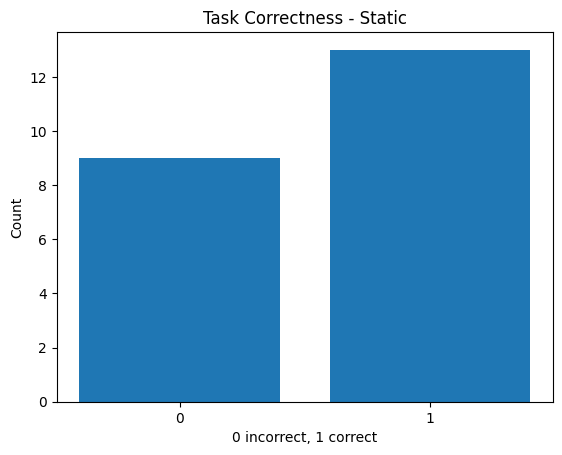

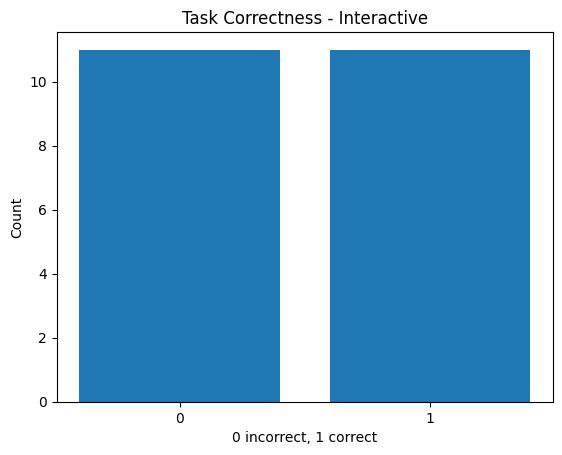

In [64]:
#Plot
task_correct_categories=[0,1]
static_count=task_static.value_counts().reindex([0,1],fill_value=0)
interactive_count=task_interactive.value_counts().reindex([0,1],fill_value=0)


plt.bar(task_correct_categories,static_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Task Correctness - Static')
plt.xticks([0, 1], ['0', '1'])
plt.show()

plt.bar(task_correct_categories,interactive_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Task Correctness - Interactive')
plt.xticks([0, 1], ['0', '1'])
plt.show()



In [65]:
#Now lets delve deeper and look at each task
#Static df--task1
static_df_task1=static_df[static_df['task']==1]
#Static df--task 2
static_df_task2=static_df[static_df['task']==2]
#Interactive df--task 1
interactive_df_task1=interactive_df[interactive_df['task']==1]
#Interactive df--task 2
interactive_df_task2=interactive_df[interactive_df['task']==2]
print(static_df_task1)
print(static_df_task1.dtypes)
print(static_df_task1['task_correct'])
#print(static_df_task2)
#print(interactive_df_task1)
#print(interactive_df_task2)

                submitted_at participant_id  group condition  task  route  \
2   2026-11-06T18:29:16.949Z              8      2    Static     1    147   
4   2026-11-06T19:28:51.852Z          p1864      1    Static     1     22   
10  2026-11-07T02:06:57.295Z           P007      2    Static     1    147   
12  2026-11-09T21:07:10.253Z           P432      1    Static     1     22   
16  2026-11-10T22:43:55.919Z              3      1    Static     1     22   
20  2026-11-11T23:50:26.912Z          P5555      1    Static     1     22   
24  2026-11-13T00:08:07.818Z          P7777      1    Static     1     22   
30  2026-11-13T00:25:51.921Z          P5556      2    Static     1    147   
32  2026-11-13T01:50:39.269Z           P010      1    Static     1     22   
38  2026-11-13T02:02:18.580Z           P011      2    Static     1    147   
42  2026-11-13T02:09:16.683Z           P012      2    Static     1    147   

               answer_stop  previous_headway  actual_next_headway  \
2    M

In [66]:
#Lets look at the correctness by type
static_task1=static_df_task1['task_correct']
static_task2=static_df_task2['task_correct']
interactive_task1=interactive_df_task1['task_correct']
interactive_task2=interactive_df_task2['task_correct']

print(static_task1)
print(static_task2)
print(interactive_task1)
print(interactive_task2)

2     1
4     0
10    1
12    1
16    1
20    1
24    1
30    0
32    1
38    1
42    1
Name: task_correct, dtype: int64
3     0
5     0
11    0
13    1
17    1
21    1
25    0
31    0
33    1
39    0
43    0
Name: task_correct, dtype: int64
0     1
6     1
8     0
14    0
18    1
22    1
26    1
28    0
34    1
36    1
40    0
Name: task_correct, dtype: int64
1     0
7     0
9     1
15    0
19    0
23    1
27    0
29    0
35    0
37    1
41    1
Name: task_correct, dtype: int64


In [67]:
#Plot
task_correct_categories=[0,1]
static_task1_count=static_task1.value_counts().reindex([0,1],fill_value=0)
static_task2_count=static_task2.value_counts().reindex([0,1],fill_value=0)
interactive_task1_count=interactive_task1.value_counts().reindex([0,1],fill_value=0)
interactive_task2_count=interactive_task2.value_counts().reindex([0,1],fill_value=0)



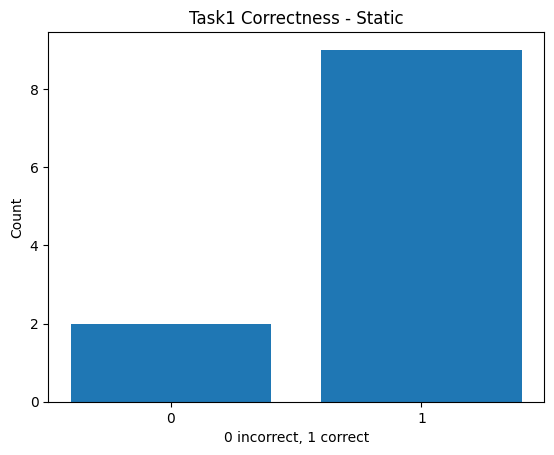

In [68]:
plt.bar(task_correct_categories,static_task1_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Task1 Correctness - Static')
plt.xticks([0, 1], ['0', '1'])
plt.show()

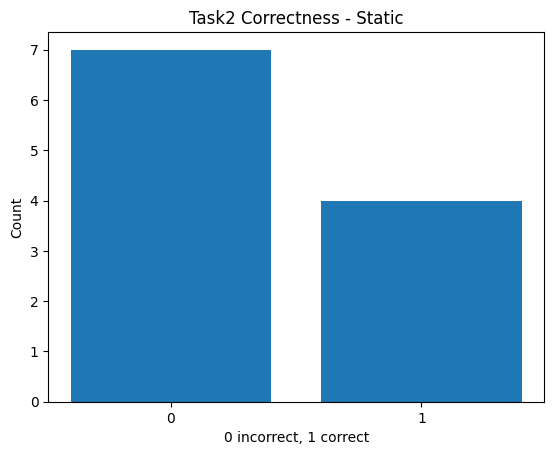

In [70]:
plt.bar(task_correct_categories,static_task2_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Task2 Correctness - Static')
plt.xticks([0, 1], ['0', '1'])
plt.show()

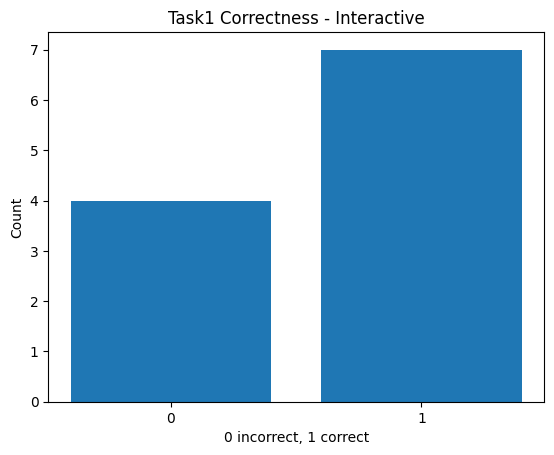

In [71]:
plt.bar(task_correct_categories,interactive_task1_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Task1 Correctness - Interactive')
plt.xticks([0, 1], ['0', '1'])
plt.show()

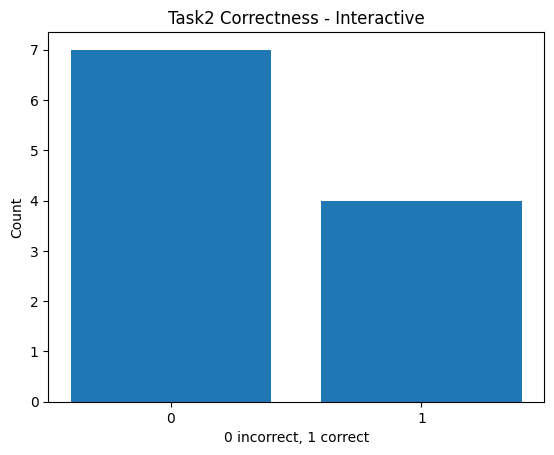

In [94]:
plt.bar(task_correct_categories,interactive_task2_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Task2 Correctness - Interactive')
plt.xticks([0, 1], ['0', '1'])
plt.show()

Now lets look at individual tasks that are discrete

In [90]:
#Static df--Note if you selected the right stop the route will be correct
static_stop_correct=static_df['stop_correct']
static_previous_correct=static_df['previous_correct']
static_actual_correct=static_df['actual_correct']
static_direction_correct=static_df['direction_correct']
static_mean1_correct=static_df['mean1_correct']
static_mean2_correct=static_df['mean2_correct']


#Interactive
interactive_stop_correct=interactive_df['stop_correct']
interactive_previous_correct=interactive_df['previous_correct']
interactive_actual_correct=interactive_df['actual_correct']
interactive_direction_correct=interactive_df['direction_correct']
interactive_mean1_correct=interactive_df['mean1_correct']
interactive_mean2_correct=interactive_df['mean2_correct']


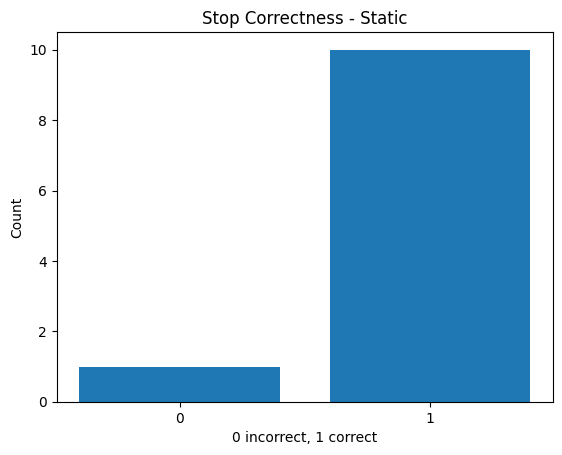

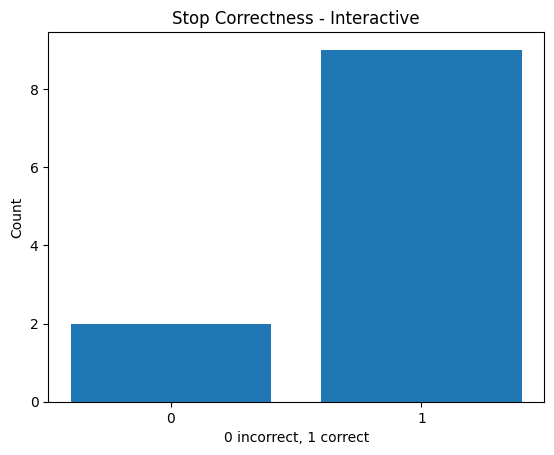

In [91]:
#Plot Stop Correct compare static to interactive
stop_correct_categories=[0,1]
static_stop_count=static_stop_correct.value_counts().reindex([0,1],fill_value=0)
interactive_stop_count=interactive_stop_correct.value_counts().reindex([0,1],fill_value=0)
plt.bar(stop_correct_categories,static_stop_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Stop Correctness - Static')
plt.xticks([0, 1], ['0', '1'])
plt.figure()
plt.bar(stop_correct_categories,interactive_stop_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Stop Correctness - Interactive')
plt.xticks([0, 1], ['0', '1'])
plt.show()

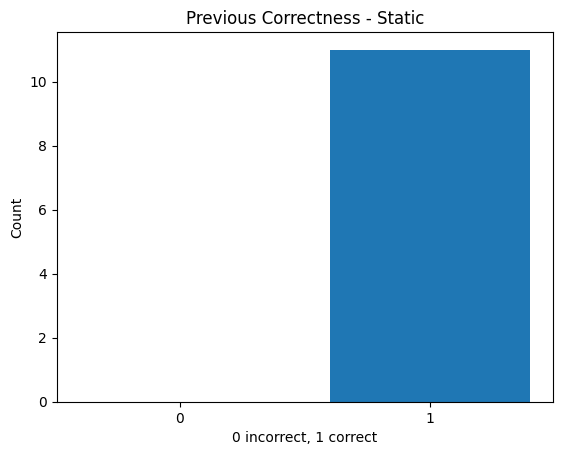

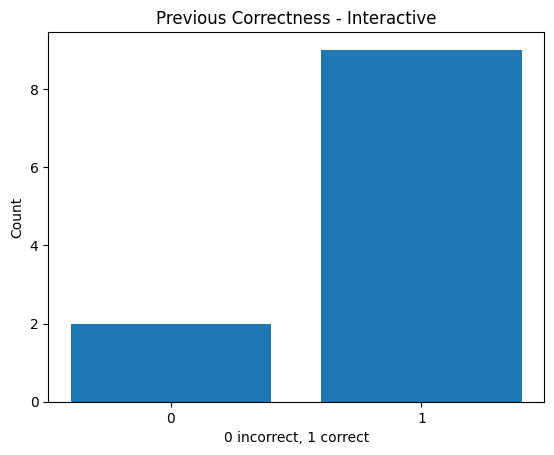

In [92]:
#Previous Correct
previous_correct_categories=[0,1]
static_previous_count=static_previous_correct.value_counts().reindex([0,1],fill_value=0)
interactive_previous_count=interactive_previous_correct.value_counts().reindex([0,1],fill_value=0)
plt.bar(previous_correct_categories,static_previous_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Previous Correctness - Static')
plt.xticks([0, 1], ['0', '1'])
plt.figure()
plt.bar(previous_correct_categories,interactive_previous_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Previous Correctness - Interactive')
plt.xticks([0, 1], ['0', '1'])
plt.show()

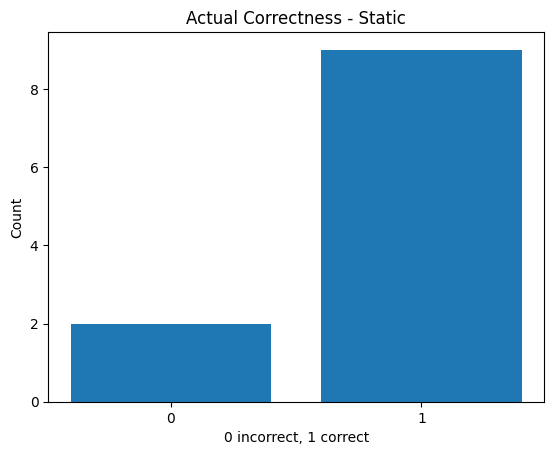

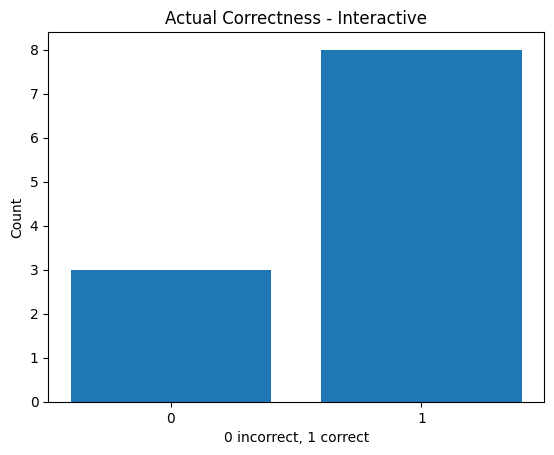

In [93]:
#Actual
actual_correct_categories=[0,1]
static_actual_count=static_actual_correct.value_counts().reindex([0,1],fill_value=0)
interactive_actual_count=interactive_actual_correct.value_counts().reindex([0,1],fill_value=0)
plt.bar(actual_correct_categories,static_actual_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Actual Correctness - Static')
plt.xticks([0, 1], ['0', '1'])
plt.figure()
plt.bar(actual_correct_categories,interactive_actual_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Actual Correctness - Interactive')
plt.xticks([0, 1], ['0', '1'])
plt.show()

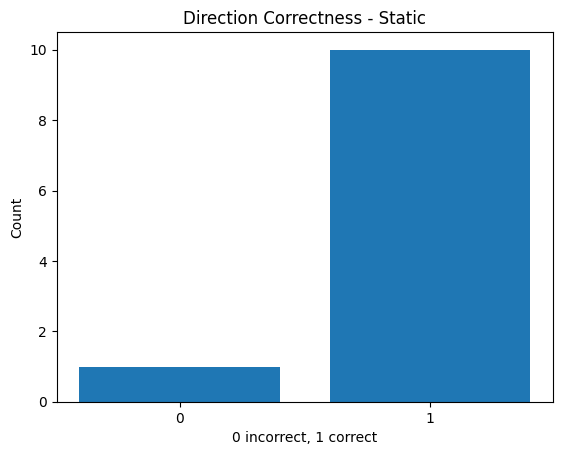

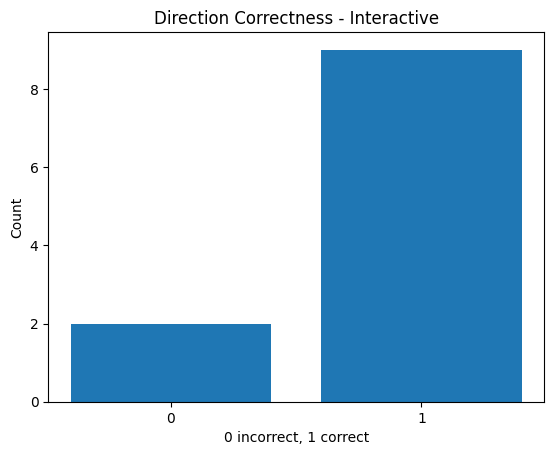

In [95]:
#Direction Correct
direction_correct_categories=[0,1]
static_direction_count=static_direction_correct.value_counts().reindex([0,1],fill_value=0)
interactive_direction_count=interactive_direction_correct.value_counts().reindex([0,1],fill_value=0)
plt.bar(direction_correct_categories,static_direction_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Direction Correctness - Static')
plt.xticks([0, 1], ['0', '1'])
plt.figure()
plt.bar(direction_correct_categories,interactive_direction_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Direction Correctness - Interactive')
plt.xticks([0, 1], ['0', '1'])
plt.show()

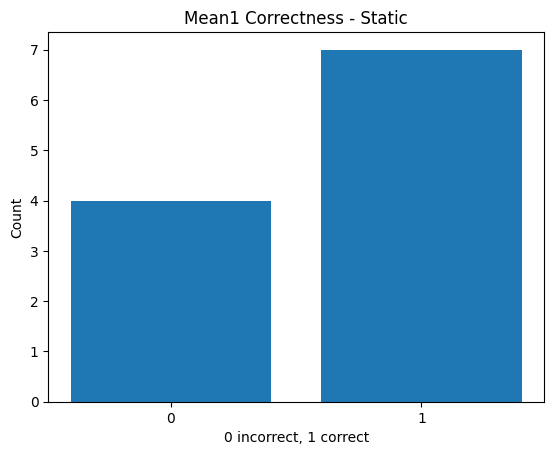

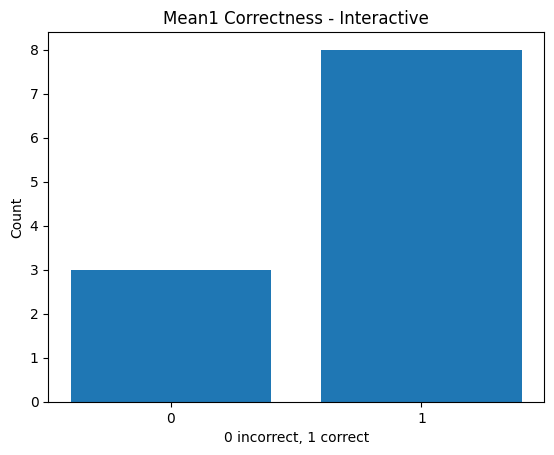

In [96]:
#Mean 1
mean1_correct_categories=[0,1]
static_mean1_count=static_mean1_correct.value_counts().reindex([0,1],fill_value=0)
interactive_mean1_count=interactive_mean1_correct.value_counts().reindex([0,1],fill_value=0)
plt.bar(mean1_correct_categories,static_mean1_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Mean1 Correctness - Static')
plt.xticks([0, 1], ['0', '1'])
plt.figure()
plt.bar(mean1_correct_categories,interactive_mean1_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Mean1 Correctness - Interactive')
plt.xticks([0, 1], ['0', '1'])
plt.show()

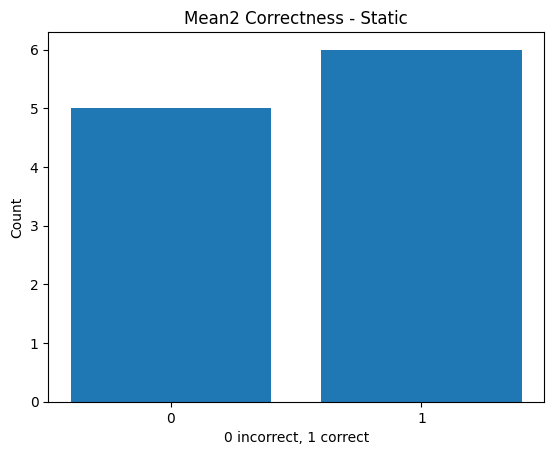

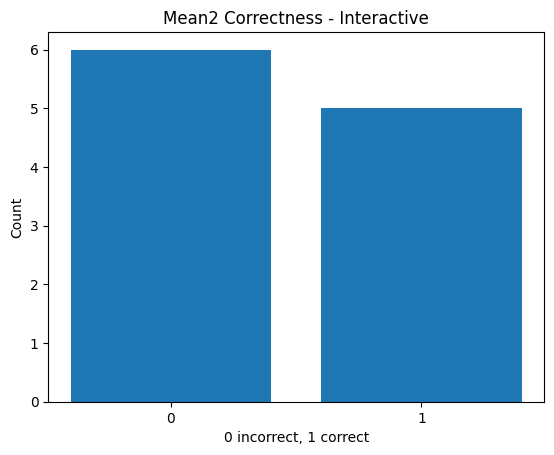

In [97]:
#Mean 2
mean2_correct_categories=[0,1]
static_mean2_count=static_mean2_correct.value_counts().reindex([0,1],fill_value=0)
interactive_mean2_count=interactive_mean2_correct.value_counts().reindex([0,1],fill_value=0)
plt.bar(mean2_correct_categories,static_mean2_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Mean2 Correctness - Static')
plt.xticks([0, 1], ['0', '1'])
plt.figure()
plt.bar(mean2_correct_categories,interactive_mean2_count)
plt.xlabel("0 incorrect, 1 correct")
plt.ylabel('Count')
plt.title('Mean2 Correctness - Interactive')
plt.xticks([0, 1], ['0', '1'])
plt.show()

Lets look at Mean Time Guesses and See Spread of Guess How Wrong they were from the Correct

In [ ]:
#Lets look at the error rates for the averages--with task one selecting extrema, you are either right or wrong, but with average time you might just be slightly off and exceed the threshold

In [80]:
print(static_df)
print(interactive_df)

#Static
static_mean1=static_df['mean1_abs_error']
static_mean2=static_df['mean2_abs_error']

#Interactive
interactive_mean1=interactive_df['mean1_abs_error']
interactive_mean2=interactive_df['mean2_abs_error']


                submitted_at participant_id  group condition  task  route  \
2   2026-11-06T18:29:16.949Z              8      2    Static     1    147   
3   2026-11-06T18:34:31.024Z              8      2    Static     2    146   
4   2026-11-06T19:28:51.852Z          p1864      1    Static     1     22   
5   2026-11-06T19:32:34.023Z          p1864      1    Static     2     36   
10  2026-11-07T02:06:57.295Z           P007      2    Static     1    147   
11  2026-11-07T02:09:31.795Z           P007      2    Static     2    146   
12  2026-11-09T21:07:10.253Z           P432      1    Static     1     22   
13  2026-11-09T21:11:26.936Z           P432      1    Static     2     36   
16  2026-11-10T22:43:55.919Z              3      1    Static     1     22   
17  2026-11-10T22:47:56.098Z              3      1    Static     2     36   
20  2026-11-11T23:50:26.912Z          P5555      1    Static     1     22   
21  2026-11-11T23:51:55.433Z          P5555      1    Static     2     36   

In [81]:
print(static_mean1)
print(static_mean2)
#Remove nan
static_mean1=static_mean1.dropna()
static_mean2=static_mean2.dropna()
interactive_mean1=interactive_mean1.dropna()
interactive_mean2=interactive_mean2.dropna()


2      NaN
3      1.8
4      NaN
5      3.6
10     NaN
11     0.2
12     NaN
13     0.4
16     NaN
17     0.4
20     NaN
21     0.6
24     NaN
25     1.6
30     NaN
31    15.2
32     NaN
33     0.6
38     NaN
39     0.2
42     NaN
43     0.2
Name: mean1_abs_error, dtype: float64
2     NaN
3     0.7
4     NaN
5     5.0
10    NaN
11    7.4
12    NaN
13    0.0
16    NaN
17    0.0
20    NaN
21    0.0
24    NaN
25    0.0
30    NaN
31    3.6
32    NaN
33    0.0
38    NaN
39    7.4
42    NaN
43    2.4
Name: mean2_abs_error, dtype: float64


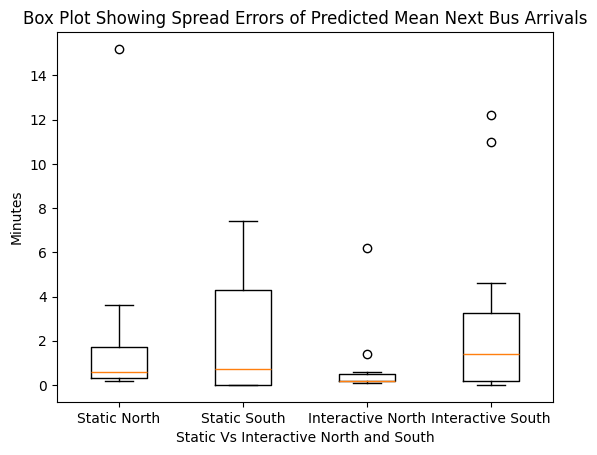

In [88]:
#Mean 1 is North Mean 2 is South
values_box=[static_mean1,static_mean2,interactive_mean1,interactive_mean2]
plt.boxplot(values_box, tick_labels=['Static North','Static South','Interactive North','Interactive South'])
plt.title("Box Plot Showing Spread Errors of Predicted Mean Next Bus Arrivals")
plt.ylabel("Minutes")
plt.xlabel("Static Vs Interactive North and South")
plt.show()

Clearly can see its tighter for interactive. Note interactive southbound has an outlier that creates some issues.

Now lets look at the spread of times it took to complete the tasks

In [106]:
#Time
static_time1=static_df.loc[static_df['task']==1,'elapsed_seconds']
static_time2=static_df.loc[static_df['task']==2,'elapsed_seconds']
interactive_time1=interactive_df.loc[interactive_df['task']==1,'elapsed_seconds']
interactive_time2=interactive_df.loc[interactive_df['task']==2,'elapsed_seconds']
print(static_time1)
print(static_time2)
print(interactive_time1)
print(interactive_time2)


2     176.64
4     759.32
10    197.80
12    547.70
16    216.97
20    125.24
24     87.91
30     13.78
32     86.25
38     71.07
42     62.52
Name: elapsed_seconds, dtype: float64
3     314.06
5     222.10
11    154.47
13    256.65
17    240.16
21     88.43
25     91.96
31     12.76
33    187.09
39     76.25
43     52.51
Name: elapsed_seconds, dtype: float64
0     224.76
6     481.34
8     155.21
14    337.24
18    131.45
22     59.20
26     57.60
28    384.94
34     63.70
36     81.28
40    153.42
Name: elapsed_seconds, dtype: float64
1     225.03
7     445.10
9     531.80
15    277.24
19    155.01
23    105.27
27     97.44
29     75.69
35    155.38
37    109.30
41     67.58
Name: elapsed_seconds, dtype: float64


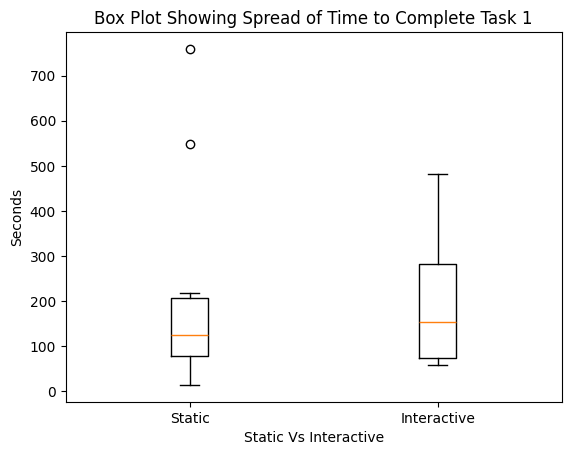

In [107]:
#Plot
#Compare task 1
values_box=[static_time1,interactive_time1]
plt.boxplot(values_box, tick_labels=['Static','Interactive'])
plt.title("Box Plot Showing Spread of Time to Complete Task 1")
plt.ylabel("Seconds")
plt.xlabel("Static Vs Interactive")
plt.show()

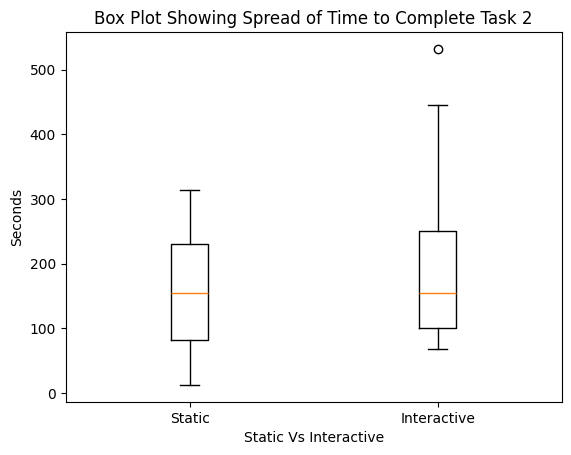

In [108]:
#Plot
#Compare task 2
values_box=[static_time2,interactive_time2]
plt.boxplot(values_box, tick_labels=['Static','Interactive'])
plt.title("Box Plot Showing Spread of Time to Complete Task 2")
plt.ylabel("Seconds")
plt.xlabel("Static Vs Interactive")
plt.show()

In [115]:
#Lets Look at Confidence Intervals by task
static_confidence1=static_df.loc[static_df['task']==1,'confidence']
static_confidence2=static_df.loc[static_df['task']==2,'confidence']
interactive_confidence1=interactive_df.loc[interactive_df['task']==1,'confidence']
interactive_confidence2=interactive_df.loc[interactive_df['task']==2,'confidence']
print(static_confidence1)
print(static_confidence2)
print(interactive_confidence1)
print(interactive_confidence2)

2     4
4     5
10    3
12    4
16    4
20    5
24    5
30    5
32    4
38    5
42    4
Name: confidence, dtype: int64
3     3
5     5
11    3
13    3
17    4
21    5
25    5
31    5
33    3
39    4
43    4
Name: confidence, dtype: int64
0     4
6     5
8     5
14    4
18    5
22    5
26    5
28    5
34    5
36    5
40    5
Name: confidence, dtype: int64
1     4
7     5
9     2
15    3
19    5
23    3
27    4
29    5
35    4
37    4
41    4
Name: confidence, dtype: int64


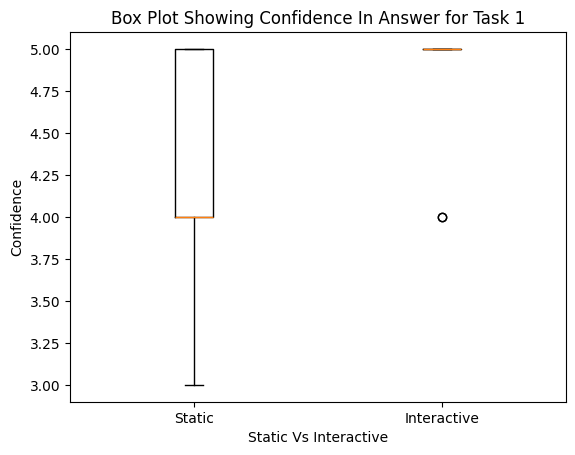

In [122]:
#Plot
#Compare task 1
values_box=[static_confidence1,interactive_confidence1]
plt.boxplot(values_box, tick_labels=['Static','Interactive'])
plt.title("Box Plot Showing Confidence In Answer for Task 1")
plt.ylabel("Confidence")
plt.xlabel("Static Vs Interactive")
plt.show()


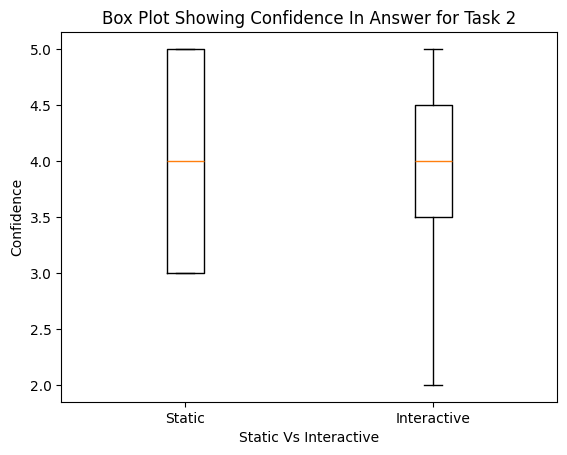

In [123]:
#Plot
values_box=[static_confidence2,interactive_confidence2]
plt.boxplot(values_box, tick_labels=['Static','Interactive'])
plt.title("Box Plot Showing Confidence In Answer for Task 2")
plt.ylabel("Confidence")
plt.xlabel("Static Vs Interactive")
plt.show()

In [118]:
#Difficulty
static_difficulty1=static_df.loc[static_df['task']==1,'difficulty']
static_difficulty2=static_df.loc[static_df['task']==2,'difficulty']
interactive_difficulty1=interactive_df.loc[interactive_df['task']==1,'difficulty']
interactive_difficulty2=interactive_df.loc[interactive_df['task']==2,'difficulty']

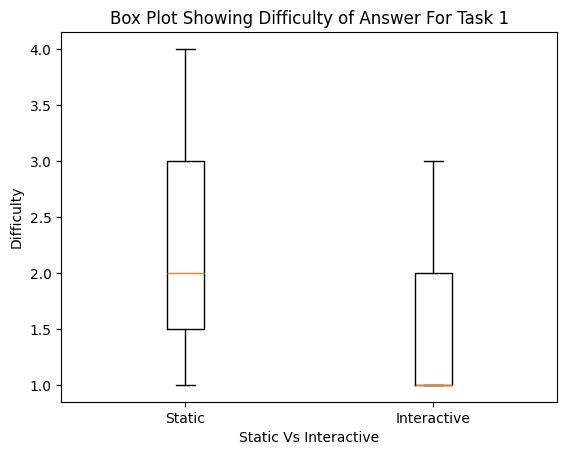

In [124]:
#Plot
values_box=[static_difficulty1,interactive_difficulty1]
plt.boxplot(values_box, tick_labels=['Static','Interactive'])
plt.title("Box Plot Showing Difficulty of Answer For Task 1")
plt.ylabel("Difficulty")
plt.xlabel("Static Vs Interactive")
plt.show()

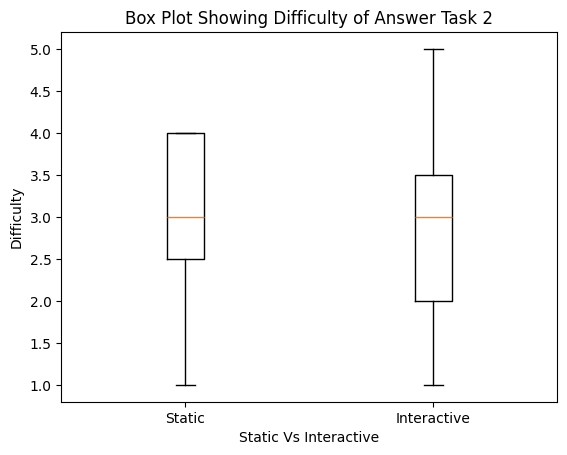

In [125]:
values_box=[static_difficulty2,interactive_difficulty2]
plt.boxplot(values_box, tick_labels=['Static','Interactive'])
plt.title("Box Plot Showing Difficulty of Answer Task 2")
plt.ylabel("Difficulty")
plt.xlabel("Static Vs Interactive")
plt.show()